In [1]:
# Cell 1: same split as before, benign-only training data
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve

df = pd.read_parquet("../data/sample.parquet")
df["Label"] = df["Label"].str.replace("�", "-", regex=False)
X = df.drop(columns=["Label", "is_attack"]); y = df["Label"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)

benign = X_train[y_train == "BENIGN"]
b_fit, b_val = train_test_split(benign, test_size=0.2, random_state=42)
print(b_fit.shape, b_val.shape)

(28000, 78) (7000, 78)


In [2]:
# Cell 2: train Isolation Forest on benign traffic only
iso = IsolationForest(n_estimators=200, max_samples=1024,
                      n_jobs=-1, random_state=42)
iso.fit(b_fit)

,n_estimators,200
,max_samples,1024
,contamination,'auto'
,max_features,1.0
,bootstrap,False
,n_jobs,-1
,random_state,42
,verbose,0
,warm_start,False


ROC-AUC: 0.7699
Attack recall: 0.132 | False alarm rate: 0.0095


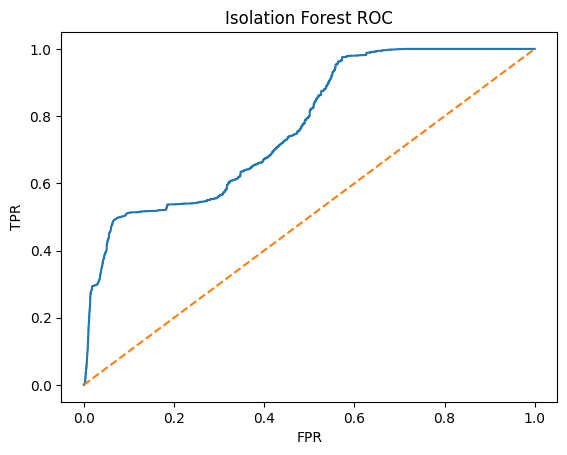

In [3]:
# Cell 3: score the test set, pick threshold from held-out benign (1% false alarms)
test_score = -iso.score_samples(X_test)          # higher = more anomalous
val_score  = -iso.score_samples(b_val)
thr = np.percentile(val_score, 99)

true_bin = (y_test != "BENIGN").astype(int)
print("ROC-AUC:", round(roc_auc_score(true_bin, test_score), 4))

pred_bin = (test_score > thr).astype(int)
tp = ((true_bin==1)&(pred_bin==1)).sum(); fn = ((true_bin==1)&(pred_bin==0)).sum()
fp = ((true_bin==0)&(pred_bin==1)).sum(); tn = ((true_bin==0)&(pred_bin==0)).sum()
print("Attack recall:", round(tp/(tp+fn), 4), "| False alarm rate:", round(fp/(fp+tn), 4))

fpr, tpr, _ = roc_curve(true_bin, test_score)
plt.plot(fpr, tpr); plt.plot([0,1],[0,1],"--"); plt.xlabel("FPR"); plt.ylabel("TPR")
plt.title("Isolation Forest ROC"); plt.show()

In [4]:
# Cell 4: Isolation Forest detection rate per attack type
res = pd.DataFrame({"Label": y_test.values, "flag": pred_bin})
print(res.groupby("Label")["flag"].mean().round(3).sort_values())

Label
DoS GoldenEye                 0.000
FTP-Patator                   0.000
PortScan                      0.000
SSH-Patator                   0.000
Web Attack - Brute Force      0.000
Web Attack - Sql Injection    0.000
Web Attack - XSS              0.005
BENIGN                        0.009
Bot                           0.027
DDoS                          0.072
DoS Slowhttptest              0.076
DoS slowloris                 0.191
Infiltration                  0.364
DoS Hulk                      0.384
Heartbleed                    1.000
Name: flag, dtype: float64


In [5]:
# Cell 5: the key experiment - attacks the classifier has NEVER seen
# Train RF without one attack class, then see how often it flags that class as non-BENIGN
iso_rate = res.groupby("Label")["flag"].mean()
rows = []
for atk in ["DDoS", "DoS Hulk", "PortScan", "Bot", "FTP-Patator",
            "SSH-Patator", "DoS slowloris", "Web Attack - Brute Force"]:
    keep = y_train != atk
    rf = RandomForestClassifier(n_estimators=50, class_weight="balanced_subsample",
                                n_jobs=-1, random_state=42)
    rf.fit(X_train[keep], y_train[keep])
    p = rf.predict(X_test[y_test == atk])
    rows.append({"unseen_attack": atk,
                 "RF_detects": round((p != "BENIGN").mean(), 3),
                 "IsoForest_detects": round(iso_rate[atk], 3)})
print(pd.DataFrame(rows))

              unseen_attack  RF_detects  IsoForest_detects
0                      DDoS       0.629              0.072
1                  DoS Hulk       0.083              0.384
2                  PortScan       0.002              0.000
3                       Bot       0.000              0.027
4               FTP-Patator       0.286              0.000
5               SSH-Patator       0.034              0.000
6             DoS slowloris       0.692              0.191
7  Web Attack - Brute Force       0.841              0.000


In [1]:
import pandas as pd, numpy as np, joblib, os
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, IsolationForest

os.makedirs("../src", exist_ok=True)

# load + same split as before
df = pd.read_parquet("../data/sample.parquet")
df["Label"] = df["Label"].str.replace("�", "-", regex=False)
X = df.drop(columns=["Label", "is_attack"]); y = df["Label"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)

# 1) Random Forest
rf = RandomForestClassifier(n_estimators=100, class_weight="balanced_subsample",
                            n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
joblib.dump({"model": rf, "features": list(X.columns)}, "../src/rf_baseline.joblib")
print("saved rf_baseline.joblib")

# 2) Isolation Forest (log-transformed, benign only) + 3 thresholds
b_fit, b_val = train_test_split(X_train[y_train == "BENIGN"], test_size=0.2, random_state=42)
iso = IsolationForest(n_estimators=200, max_samples=1024, n_jobs=-1, random_state=42)
iso.fit(np.log1p(b_fit.clip(lower=0)))
val_s = -iso.score_samples(np.log1p(b_val.clip(lower=0)))
thresholds = {"low": float(np.percentile(val_s, 99)),
              "medium": float(np.percentile(val_s, 95)),
              "high": float(np.percentile(val_s, 90))}
joblib.dump({"model": iso, "features": list(X.columns), "thresholds": thresholds},
            "../src/iso_forest.joblib")
print("saved iso_forest.joblib", thresholds)

# 3) demo CSV for the app
df.sample(5000, random_state=1).drop(columns=["is_attack"]).to_csv("../data/demo.csv", index=False)
print("saved demo.csv")

saved rf_baseline.joblib
saved iso_forest.joblib {'low': 0.6088504837572377, 'medium': 0.5548162500422529, 'high': 0.520125923930044}
saved demo.csv
